# Cleaning data

- download the datasets and mount on drive for faster access and persistence

In [ ]:
from google.colab import drive
import kagglehub
import os

drive.mount('/content/drive')

# downloading the data sets (the first 2 are for training & validation ; the last one is for cross-validation)
path_fares = kagglehub.dataset_download("faresabbasai2022/skin-burns-dataset")
print("fares: ", path_fares)

path_shubham = kagglehub.dataset_download("shubhambaid/skin-burn-dataset")
print("shubham: ", path_shubham)

path_sayeem = kagglehub.dataset_download("sayeemzzzaman/burn-dataset-cleanedv2-augmented")
print("sayeem:", path_sayeem)

print("Datasets downloaded successfully")

Mounted at /content/drive


100%|██████████| 1.42G/1.42G [01:19<00:00, 19.3MB/s]

Extracting files...


fares:  /root/.cache/kagglehub/datasets/faresabbasai2022/skin-burns-dataset/versions/1
Using Colab cache for faster access to the 'skin-burn-dataset' dataset.
shubham:  /kaggle/input/skin-burn-dataset


100%|██████████| 92.3M/92.3M [00:05<00:00, 16.2MB/s]

Extracting files...


sayeem: /root/.cache/kagglehub/datasets/sayeemzzzaman/burn-dataset-cleanedv2-augmented/versions/1
Datasets downloaded successfully


- split data in directories & convert images to a certain format and save them in drive ;
- create final folders with cleaned images

In [ ]:
# it takes about 3 m 40 s

import os
import shutil
import hashlib
import time
import numpy as np
from PIL import Image
from collections import defaultdict
from sklearn.model_selection import train_test_split
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

"""
# single base directory with leak-free train/val/test splits instead of separate train_val/cross-validation folders
# previously, we isolated Sayeem into cross_value_clean and then into 80/20 train/test, which lcoked away a bunch of 3rd degree burns
# and caused class dominance problems ; moreover, the train set caused the Fares datases that already had augmented images to get even
# more duplicate images due to the same logic applying to all folders and hence all subdirectories
"""

t0 = time.time() # record the time it takes

BASE_DIR = '/content/Burn_Project_V2'
if os.path.exists(BASE_DIR):
    shutil.rmtree(BASE_DIR)

for split in ['train', 'val', 'test']:
    for deg in ['degree_1', 'degree_2', 'degree_3']:
        os.makedirs(os.path.join(BASE_DIR, split, deg), exist_ok=True)

# catches resized, compressed, or slightly altered duplicates that MD5 missed previously, causing unecesarry data duping
def fast_canonical_dhash(img):
    # converts to 9x9 grayscale NumPy array once; eliminates the redundant 6 PIL allocations
    gray_small = np.asarray(img.convert('L').resize((9, 9), Image.Resampling.BILINEAR), dtype=np.int16)
    variants = [
        gray_small,
        np.fliplr(gray_small),  # uses instant NumPy array views instead of PIL ImageOps.mirror/flip/rotate
        np.flipud(gray_small),
        np.rot90(gray_small, 1),
        np.rot90(gray_small, 2),
        np.rot90(gray_small, 3),
    ]
    hashes = []
    for v in variants:
        diff = v[:8, 1:] > v[:8, :-1]
        hashes.append(int(np.packbits(diff.flatten()).view(np.uint64)[0]))  # packs 64 boolean bits into a uint64 integer in C instead of slow Python power-of-2 loop
    return min(hashes)

# folder naming conventions stay the same (degree_1, degree_2, degree_3)
# cache directory listings so os.listdir() doesn't stall on Colab's filesystem
_sibling_cache = {}
def get_degree_from_folder(folder_path):
    folder_name = os.path.basename(folder_path).lower()
    if any(k in folder_name for k in ['1st', 'first', 'degree_1']): return 'degree_1'
    if any(k in folder_name for k in ['2nd', 'second', 'degree_2']): return 'degree_2'
    if any(k in folder_name for k in ['3rd', 'third', 'degree_3']): return 'degree_3'

    parent_dir = os.path.dirname(folder_path)
    if parent_dir not in _sibling_cache:
        _sibling_cache[parent_dir] = [d.lower() for d in os.listdir(parent_dir)] if os.path.exists(parent_dir) else []
    if '0' in _sibling_cache[parent_dir]:
        return {'0': 'degree_1', '1': 'degree_2', '2': 'degree_3'}.get(folder_name)
    return {'1': 'degree_1', '2': 'degree_2', '3': 'degree_3'}.get(folder_name)

tasks = []  # stores lightweight file paths + crop coordinates instead of open PIL images to prevent 6GB+ RAM bloat

# we now pool Fares and Sayeem together so training gets Sayeem's 1,000+ rare 3rd-degree burn images
for ds_path, prefix in [(path_fares, "fares"), (path_sayeem, "sayeem")]:
    for root, _, files in os.walk(ds_path):
        deg = get_degree_from_folder(root)
        if deg is None:
            continue
        for f in files:
            if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp')):
                tasks.append((os.path.join(root, f), None, deg, prefix))

# collect Shubham YOLO crops, but we raise min box size from 10px to 20px + full images
YOLO_CLASS_MAP = {'0': 'degree_1', '1': 'degree_2', '2': 'degree_3'}
shubham_images = {
    os.path.splitext(f)[0]: os.path.join(root, f)
    for root, _, files in os.walk(path_shubham)
    for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))
}

# store normalized YOLO coords without opening images sequentially
# loop through every YOLO annotation (.txt) file
for root, _, files in os.walk(path_shubham):
    # skip non-label files and the metadata 'classes.txt' file
    for f in files:
        if not f.lower().endswith('.txt') or f.lower() == 'classes.txt':
            continue
        base_name = os.path.splitext(f)[0]
        if base_name not in shubham_images:
            continue
        img_path = shubham_images[base_name]  # stores image path string so it can be referenced without keeping pixels in memory
        # read all bounding box lines inside the label file
        with open(os.path.join(root, f), 'r') as fp:
            lines = [line.strip().split() for line in fp if line.strip()]
        found_degrees = []
        for idx, parts in enumerate(lines):
            if len(parts) >= 5 and parts[0] in YOLO_CLASS_MAP:
                deg = YOLO_CLASS_MAP[parts[0]]
                found_degrees.append(deg)
                tasks.append((img_path, tuple(map(float, parts[1:5])), deg, f"shubham_crop{idx}"))
        if found_degrees:
            tasks.append((img_path, None, max(found_degrees), "shubham_full"))

print(f"Queued {len(tasks)} candidates in {time.time() - t0:.1f}s")

# decodes an image, computes MD5 + dHash on a tiny 64x64 thumbnail, and immediately frees image memory; allows parallel C-level JPEG decoding
def hash_worker(task):
    filepath, norm_box, deg, prefix = task
    try:
        with Image.open(filepath) as img:
            w_orig, h_orig = img.size
            if norm_box is not None:
                xc, yc, wb, hb = norm_box
                l, t = max(0, int((xc - wb / 2) * w_orig)), max(0, int((yc - hb / 2) * h_orig))
                r, b = min(w_orig, int((xc + wb / 2) * w_orig)), min(h_orig, int((yc + hb / 2) * h_orig))
                # only take "valid" bounding boxes (big enough)
                if r - l < 20 or b - t < 20:
                    return None
                img_rgb = img.convert('RGB').crop((l, t, r, b))
            else:
                # libjpeg DCT fast-scaling: decodes JPEGs directly at ~64x64 instead of full HD (~10x faster)
                img.draft('RGB', (64, 64))
                img_rgb = img.convert('RGB')

            thumb = img_rgb.resize((64, 64), Image.Resampling.BILINEAR)
            md5 = hashlib.md5(thumb.tobytes()).hexdigest()
            phash = fast_canonical_dhash(thumb)
            return (md5, phash, filepath, norm_box, deg, prefix)
    except Exception:
        return None

NUM_WORKERS = 4
with ThreadPoolExecutor(max_workers=NUM_WORKERS) as pool:
    hashed_results = [
        res for res in tqdm(pool.map(hash_worker, tasks, chunksize=64), total=len(tasks), desc="1/2 Deduplicating")
        if res is not None
    ]

# deduplicate exact MD5 matches first, then cluster pre-augmented variants by canonical dHash
# update to 3-way split: train updates the NN's weights, val guides early stopping, LROnPlateau and probability treshold tuning and test will be for the analysis
groups = defaultdict(list)
seen_exact_md5 = set()

for md5, phash, filepath, crop_box, deg, prefix in hashed_results:  # iterates over precomputed hash tuples instead of opening files sequentially
    if md5 in seen_exact_md5:
        continue
    seen_exact_md5.add(md5)
    groups[phash].append((filepath, crop_box, deg, prefix, md5[:10]))  # stores file path + crop box instead of 224x224 image tensor

# we now cap pre-augmented bloat (max 2 variants/photo for majority classes, max 4 for rare 3rd-degree burns)
clean_groups = []
for g_hash, items in groups.items():
    deg_counts = defaultdict(int)
    for _, _, d, _, _ in items:
        deg_counts[d] += 1
    group_deg = max(deg_counts, key=deg_counts.get)
    filtered_items = [it for it in items if it[2] == group_deg]

    cap = 4 if group_deg == 'degree_3' else 2
    clean_groups.append((g_hash, group_deg, filtered_items[:cap]))

group_indices = np.arange(len(clean_groups))
group_labels = [g[1] for g in clean_groups]

# stratified split by perceptual group (75% Train / 12.5% Val / 12.5% Test) so variants never leak across splits (like having way too many 3r degree images in one split)
train_g, temp_g, _, temp_labels = train_test_split(
    group_indices, group_labels, test_size=0.25, stratify=group_labels, random_state=42
)
val_g, test_g = train_test_split(
    temp_g, test_size=0.50, stratify=temp_labels, random_state=42
)

split_map = {}
for idx in train_g: split_map[idx] = 'train'
for idx in val_g:   split_map[idx] = 'val'
for idx in test_g:  split_map[idx] = 'test'

save_tasks = []  # collects final output paths for the ~7,000 kept images so disk writes can run in parallel
for idx, (_, group_deg, items) in enumerate(clean_groups):
    split_name = split_map[idx]
    # save only 1 canonical image per source group in val/test so evaluation metrics aren't skewed
    items_to_save = items if split_name == 'train' else items[:1]
    for filepath, crop_box, deg, prefix, short_md5 in items_to_save:
        out_path = os.path.join(BASE_DIR, split_name, deg, f"{prefix}_{short_md5}.jpg")
        save_tasks.append((filepath, crop_box, out_path))  # queue write tasks

# worker that loads, crops, resizes to 224x224, and saves ONLY the deduplicated images that survived filtering; avoids wasting time resizing discarded duplicates
def save_worker(item):
    filepath, norm_box, out_path = item
    try:
        with Image.open(filepath) as img:
            w_orig, h_orig = img.size
            if norm_box is not None:
                xc, yc, wb, hb = norm_box
                l, t = max(0, int((xc - wb / 2) * w_orig)), max(0, int((yc - hb / 2) * h_orig))
                r, b = min(w_orig, int((xc + wb / 2) * w_orig)), min(h_orig, int((yc + hb / 2) * h_orig))
                img_rgb = img.convert('RGB').crop((l, t, r, b))
            else:
                img.draft('RGB', (224, 224))  # fast DCT scaling to 224x224 during JPEG decode
                img_rgb = img.convert('RGB')
            img_224 = img_rgb.resize((224, 224), Image.Resampling.BILINEAR)
            img_224.save(out_path, format='JPEG', quality=95)
    except Exception:
        pass


with ThreadPoolExecutor(max_workers=NUM_WORKERS) as pool:
    list(tqdm(pool.map(save_worker, save_tasks, chunksize=32), total=len(save_tasks), desc="2/2 Saving 224x224"))

print(f"Done in {time.time() - t0:.1f}s")
for split in ['train', 'val', 'test']:
    counts = {d: len(os.listdir(os.path.join(BASE_DIR, split, d))) for d in ['degree_1', 'degree_2', 'degree_3']}
    print(f"{split.upper():<6} counts: {counts}")

Queued 42506 candidates in 18.9s


1/2 Deduplicating:   0%|          | 0/42506 [00:00<?, ?it/s]

2/2 Saving 224x224:   0%|          | 0/31848 [00:00<?, ?it/s]

Done in 152.1s
TRAIN  counts: {'degree_1': 12529, 'degree_2': 11225, 'degree_3': 1092}
VAL    counts: {'degree_1': 1901, 'degree_2': 1440, 'degree_3': 160}
TEST   counts: {'degree_1': 1902, 'degree_2': 1439, 'degree_3': 160}


- save data to drive

In [ ]:
# create permanent project directory inside Drive if it doesn't exist yet
!mkdir -p /content/drive/MyDrive/Burn_Project
# all cleaned local folders -> one .zip on Drive
!zip -r -q /content/drive/MyDrive/Burn_Project/cleaned_burn_data_v2.zip /content/Burn_Project_V2
print("Saved V2 data permanently to Drive")

Saved V2 data permanently to Drive


# Model logic

- ensure reproductibility

In [ ]:
# 31 s

import random
import os
import torch
import numpy as np
from google.colab import drive
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Forces cuDNN to use deterministic algorithms (slightly slower, but 100% repeatable)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True

seed_everything(42)

In [ ]:
from torchvision.transforms import v2

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# mount Drive -> unzip V2 dataset to local SSD if not already present
drive.mount("/content/drive")
BASE_DIR = "/content/Burn_Project_V2"
if not os.path.exists(BASE_DIR):
  !unzip -q /content/drive/MyDrive/Burn_Project/cleaned_burn_data_v2.zip -d /
  print("Unzipped cleaned V2 dataset from Drive")

# ImageNet normalization required by pretrained MobileNetV3-Large
imagenet_norm = transforms.Normalize(
    mean=[0.485, 0.456, 0.406],
    std=[0.229, 0.224, 0.225]
)

train_dir = os.path.join(BASE_DIR, "train")
val_dir = os.path.join(BASE_DIR, "val")
test_dir = os.path.join(BASE_DIR, "test")


train_transforms = v2.Compose([
    v2.RandomResizedCrop(size=224, scale=(0.60, 1.0), antialias=True),
    v2.RandomHorizontalFlip(p=0.5),
    v2.RandomApply([v2.GaussianBlur(kernel_size=5, sigma=(0.1, 2.0))], p=0.25),
    v2.RandomApply([v2.JPEG(quality=(30, 85))], p=0.30),
    v2.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# no augmentations for validation & cross-validation
eval_transforms = transforms.Compose([
    transforms.ToTensor(),
    imagenet_norm
])


# load pre-separated, leak-free train/val/test folders directly (replaces in-memory train_test_split & Subset)
train_dataset = datasets.ImageFolder(root=f'{BASE_DIR}/train', transform=train_transforms)
val_dataset   = datasets.ImageFolder(root=f'{BASE_DIR}/val',   transform=eval_transforms)
test_dataset  = datasets.ImageFolder(root=f'{BASE_DIR}/test',  transform=eval_transforms)

print("Class mapping:", train_dataset.class_to_idx)  # {'degree_1': 0, 'degree_2': 1, 'degree_3': 2}

train_targets = np.array(train_dataset.targets)
class_counts = np.bincount(train_targets)
print("Clean training counts per class (1st, 2nd, 3rd degree):", class_counts)

# smoothed inverse-power (0.85 instead of 1.0) prevents over-memorizing 3rd-degree burns while keeping batches balanced
class_weights = 1.0 / np.power(class_counts, 0.85)
sample_weights = class_weights[train_targets]

g = torch.Generator().manual_seed(42)
balanced_sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=4500,
    replacement=True,
    generator=g
)

# create DataLoaders (Note: shuffle=False is required when using a sampler)
BATCH_SIZE = 64
use_cuda = (device.type == "cuda")

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=balanced_sampler,
    num_workers=2,
    pin_memory=use_cuda,
    persistent_workers=True,
    drop_last=True           # prevents a 1-sample final batch from crashing BatchNorm1d
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=use_cuda,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=use_cuda
)

print(f"training samples per epoch: {len(balanced_sampler)}")
print(f"validation images:          {len(val_dataset)}")
print(f"holdout test images:        {len(test_dataset)}")

Using device: cuda
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Class mapping: {'degree_1': 0, 'degree_2': 1, 'degree_3': 2}
Clean training counts per class (1st, 2nd, 3rd degree): [12529 11225  1092]
training samples per epoch: 4500
validation images:          3501
holdout test images:        3501


- training the model

In [ ]:
import copy
import time
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from sklearn.metrics import f1_score

# model arhitecture: MobileNetV3-Large + Custom Head

class BurnClassifier(nn.Module):
    def __init__(self, num_classes=3, dropout_rate=0.45):
        super().__init__()
        # load pretrained MobileNetV3-Large backbone
        weights = models.MobileNet_V3_Large_Weights.DEFAULT
        self.backbone = models.mobilenet_v3_large(weights=weights)

        # MobileNetV3-Large's final classifier expects 960 features from the pooled backbone
        in_features = self.backbone.classifier[0].in_features

        # Replace the default 1000-class ImageNet head with our custom regularized head
        self.backbone.classifier = nn.Sequential(
            nn.Dropout(p=0.2),  # light feature dropout before projection (matches native MobileNetV3 design)
            nn.Linear(in_features, 512),
            nn.BatchNorm1d(512),
            nn.Hardswish(),
            nn.Dropout(p=dropout_rate),
            nn.Linear(512, num_classes)  # outputs raw logits for CrossEntropyLoss
        )

        # Apply Xavier initialization to our custom Linear layers
        self._init_custom_weights()

    def _init_custom_weights(self):
        for m in self.backbone.classifier.modules():
            if isinstance(m, nn.Linear):
                nn.init.xavier_uniform_(m.weight)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.backbone(x)

    def predict_proba(self, x):
        """returns Softmax probabilities [P(1st burn), P(2nd burn), P(3rd burn)] for JEV Decision API."""
        logits = self.forward(x)
        return torch.softmax(logits, dim=1)


model = BurnClassifier(num_classes=3, dropout_rate=0.45).to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

# training and validation functions

# automatic mixed precision (FP16) scaler cuts epoch time roughly in half
use_amp = (device.type == "cuda")
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def run_phase(model, optimizer, scheduler, num_epochs, phase_name, patience=6, best_f1=0.0, best_weights=None):
    if best_weights is None:
        best_weights = copy.deepcopy(model.state_dict())

    epochs_no_improve = 0
    best_path = '/content/drive/MyDrive/Burn_Project/best_burn_mobilenetv3_v2.pth'

    for epoch in range(1, num_epochs + 1):
        start_time = time.time()

        # training step
        model.train()
        train_loss = 0.0
        total_train_samples = 0  # exact sample count since drop_last=True drops the last 20 samples
        for images, labels in train_loader:
            images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast('cuda', enabled=use_amp):
                logits = model(images)
                loss = criterion(logits, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * images.size(0)
            total_train_samples += images.size(0)

        train_loss /= total_train_samples

        # --- VALIDATION STEP ---
        model.eval()
        val_loss = 0.0
        all_preds, all_labels = [], []

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)
                with torch.amp.autocast('cuda', enabled=use_amp):
                    logits = model(images)
                    loss = criterion(logits, labels)

                val_loss += loss.item() * images.size(0)
                preds = torch.argmax(logits, dim=1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

        val_loss /= len(val_loader.dataset)
        val_acc = (torch.tensor(all_preds) == torch.tensor(all_labels)).float().mean().item()
        val_macro_f1 = f1_score(all_labels, all_preds, average='macro')

        if scheduler is not None:
            scheduler.step(val_macro_f1)

        elapsed = time.time() - start_time
        print(f"[{phase_name}] Epoch {epoch}/{num_epochs} ({elapsed:.1f}s) | "
              f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
              f"Val Acc: {val_acc*100:.2f}% | Val Macro-F1: {val_macro_f1:.4f}")

        if val_macro_f1 > best_f1:
            best_f1 = val_macro_f1
            best_weights = copy.deepcopy(model.state_dict())
            torch.save(best_weights, best_path)
            epochs_no_improve = 0
            print(f"New best model saved (Macro-F1: {best_f1:.4f})")
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"Early stopping triggered after {epoch} epochs")
                break

    model.load_state_dict(best_weights)
    return model, best_f1, best_weights

# phase 1: warm up custom head (backbone is frozen)
print("PHASE 1: Training custom classifier head (backbone is frozen)")
for param in model.backbone.features.parameters():
    param.requires_grad = False

optimizer_p1 = optim.AdamW(model.backbone.classifier.parameters(), lr=1e-3, weight_decay=2e-4)
scheduler_p1 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p1, mode='max', factor=0.5, patience=2, min_lr=1e-5)

model, best_f1, best_weights = run_phase(
    model, optimizer_p1, scheduler_p1, num_epochs=100, phase_name="Phase 1", patience=4
)

# phase 2: fine-tune the entire network (backbone unfrozen)
print("\n--- PHASE 2: Fine-Tuning Full MobileNetV3-Large Network ---")
for param in model.backbone.features.parameters():
    param.requires_grad = True

# Use a lower learning rate for the pretrained backbone and slightly higher for the head
optimizer_p2 = optim.AdamW([
    {'params': model.backbone.features.parameters(), 'lr': 1e-4},
    {'params': model.backbone.classifier.parameters(), 'lr': 3e-4}
], weight_decay=3e-4)
scheduler_p2 = optim.lr_scheduler.ReduceLROnPlateau(optimizer_p2, mode='max', factor=0.5, patience=3, min_lr=1e-6)

model, best_f1, best_weights = run_phase(
    model, optimizer_p2, scheduler_p2, num_epochs=100, phase_name="Phase 2", patience=8,
    best_f1=best_f1, best_weights=best_weights
)

print(f"\nTraining complete! Best Validation Macro-F1: {best_f1:.4f}")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 87.8MB/s]


PHASE 1: Training custom classifier head (backbone is frozen)
[Phase 1] Epoch 1/100 (42.7s) | Train Loss: 0.8703 | Val Loss: 0.7409 | Val Acc: 70.52% | Val Macro-F1: 0.5964
New best model saved (Macro-F1: 0.5964)
[Phase 1] Epoch 2/100 (34.0s) | Train Loss: 0.7254 | Val Loss: 0.5774 | Val Acc: 77.78% | Val Macro-F1: 0.7321
New best model saved (Macro-F1: 0.7321)
[Phase 1] Epoch 3/100 (34.1s) | Train Loss: 0.6493 | Val Loss: 0.5455 | Val Acc: 80.52% | Val Macro-F1: 0.7538
New best model saved (Macro-F1: 0.7538)
[Phase 1] Epoch 4/100 (32.7s) | Train Loss: 0.6690 | Val Loss: 0.5471 | Val Acc: 80.38% | Val Macro-F1: 0.7386
[Phase 1] Epoch 5/100 (32.8s) | Train Loss: 0.6152 | Val Loss: 0.5459 | Val Acc: 80.69% | Val Macro-F1: 0.7442
[Phase 1] Epoch 6/100 (33.2s) | Train Loss: 0.6280 | Val Loss: 0.5347 | Val Acc: 81.32% | Val Macro-F1: 0.7529
[Phase 1] Epoch 7/100 (32.8s) | Train Loss: 0.6174 | Val Loss: 0.5332 | Val Acc: 81.43% | Val Macro-F1: 0.7470
Early stopping triggered after 7 epochs



HOLDOUT TEST REPORT (Standard Argmax Decision)
              precision    recall  f1-score   support

  1st Degree     0.9755    0.9621    0.9688      1902
  2nd Degree     0.9429    0.9632    0.9529      1439
  3rd Degree     0.9161    0.8875    0.9016       160

    accuracy                         0.9592      3501
   macro avg     0.9448    0.9376    0.9411      3501
weighted avg     0.9594    0.9592    0.9592      3501

--------------------------------------------------------------------
Overall Accuracy:             95.92%
Macro F1-Score:               0.9411
Cohen's Kappa:                0.9236  (>0.80 = strong clinical agreement)
Multi-Class ROC-AUC (OvR):    0.9947  (measures probability ranking quality)
Log-Loss (Calibration):       0.1315  (lower = better calibrated probabilities)
3rd-Degree Miss Rate:         11.25% (18/160 misclassified)
Critical Miss (3rd -> 1st):   1.25% (highest patient safety risk)

HOLDOUT TEST REPORT (Clinical Safety Threshold: P(3rd) >= 0.54)
       

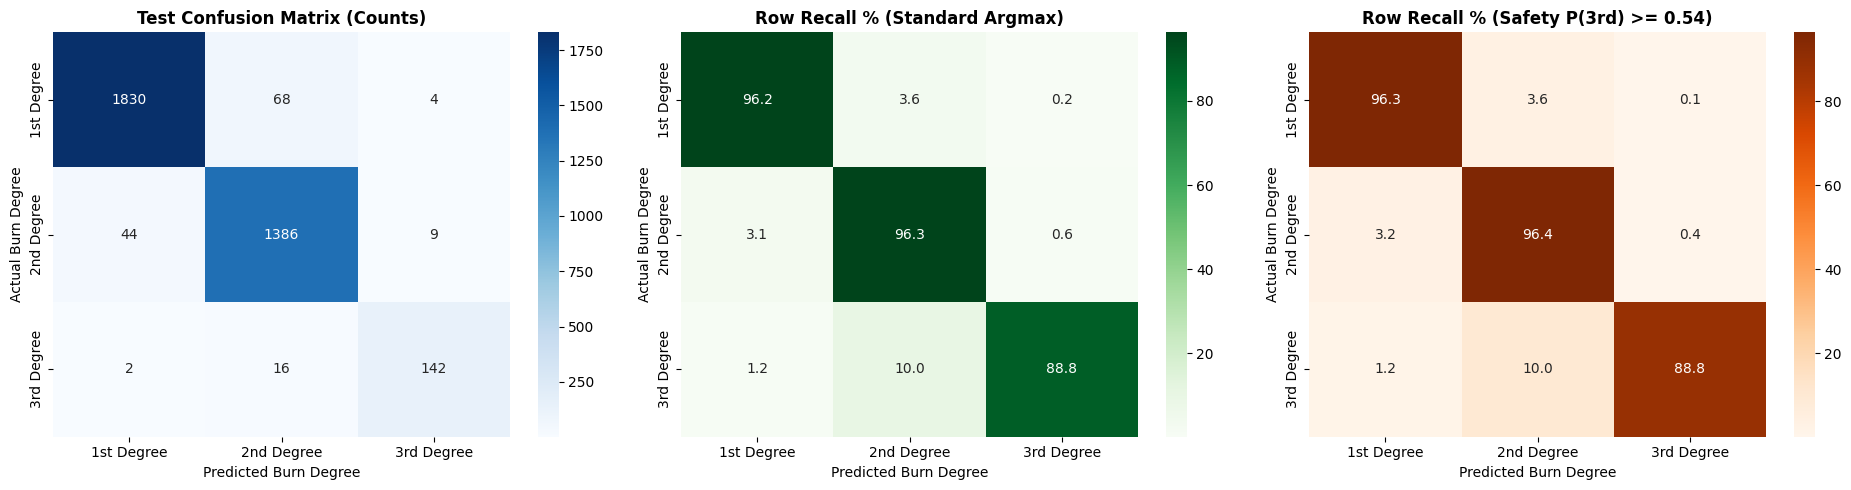

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    cohen_kappa_score,
    roc_auc_score,
    log_loss
)

best_path = '/content/drive/MyDrive/Burn_Project/best_burn_mobilenetv3_v2.pth'
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()

class_names = ['1st Degree', '2nd Degree', '3rd Degree']
use_amp = (device.type == "cuda")

def get_predictions(loader):
    labels_list, probs_list = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            with torch.amp.autocast('cuda', enabled=use_amp):
                probs = model.predict_proba(images)
            labels_list.extend(labels.numpy())
            probs_list.extend(probs.float().cpu().numpy())
    return np.array(labels_list), np.array(probs_list)

def apply_safety_threshold(probs, deg3_thresh):
  """Escalates to 3rd Degree whenever P(3rd) >= deg3_thresh; otherwise picks argmax(1st, 2nd)."""
  preds = np.argmax(probs[:, :2], axis=1)
  preds[probs[:, 2] >= deg3_thresh] = 2
  return preds

# step 1: tune 3rd-degree safety threshold strictly on val set (zero test leakage)
val_true, val_prob = get_predictions(val_loader)
best_tau = 0.50
best_val_f1_safe = -1.0

for tau in np.arange(0.20, 0.71, 0.02):
    val_pred_tau = apply_safety_threshold(val_prob, tau)
    deg3_rec = (val_pred_tau[val_true == 2] == 2).mean()
    mf1 = f1_score(val_true, val_pred_tau, average='macro')
    # Target >= 85% 3rd-degree recall while maximizing overall Macro-F1
    if deg3_rec >= 0.85 and mf1 > best_val_f1_safe:
        best_val_f1_safe = mf1
        best_tau = round(float(tau), 2)

# fallback if no threshold hits 85% recall: pick threshold with highest Macro-F1
if best_val_f1_safe < 0:
    for tau in np.arange(0.25, 0.51, 0.02):
        val_pred_tau = apply_safety_threshold(val_prob, tau)
        mf1 = f1_score(val_true, val_pred_tau, average='macro')
        if mf1 > best_val_f1_safe:
            best_val_f1_safe = mf1
            best_tau = round(float(tau), 2)

# step 2: evaluate on unseen holdout test set)
y_true, y_prob = get_predictions(test_loader)
y_pred = np.argmax(y_prob, axis=1)
y_pred_safe = apply_safety_threshold(y_prob, best_tau)

def print_eval_summary(title, yt, yp, yprob):
    print("=" * 68)
    print(title)
    print("=" * 68)
    print(classification_report(yt, yp, target_names=class_names, digits=4))

    overall_acc = (yt == yp).mean()
    macro_f1    = f1_score(yt, yp, average='macro')
    kappa       = cohen_kappa_score(yt, yp)
    roc_auc     = roc_auc_score(yt, yprob, multi_class='ovr', average='macro')
    calib_loss  = log_loss(yt, yprob)

    deg3_mask = (yt == 2)
    missed_deg3 = np.sum(yp[deg3_mask] != 2)
    total_deg3  = np.sum(deg3_mask)
    under_triage_rate  = (missed_deg3 / total_deg3) * 100
    critical_miss_rate = (np.sum(yp[deg3_mask] == 0) / total_deg3) * 100

    print("-" * 68)
    print(f"Overall Accuracy:             {overall_acc * 100:.2f}%")
    print(f"Macro F1-Score:               {macro_f1:.4f}")
    print(f"Cohen's Kappa:                {kappa:.4f}  (>0.80 = strong clinical agreement)")
    print(f"Multi-Class ROC-AUC (OvR):    {roc_auc:.4f}  (measures probability ranking quality)")
    print(f"Log-Loss (Calibration):       {calib_loss:.4f}  (lower = better calibrated probabilities)")
    print(f"3rd-Degree Miss Rate:         {under_triage_rate:.2f}% ({missed_deg3}/{total_deg3} misclassified)")
    print(f"Critical Miss (3rd -> 1st):   {critical_miss_rate:.2f}% (highest patient safety risk)")
    print("=" * 68 + "\n")

print_eval_summary("HOLDOUT TEST REPORT (Standard Argmax Decision)", y_true, y_pred, y_prob)
print_eval_summary(f"HOLDOUT TEST REPORT (Clinical Safety Threshold: P(3rd) >= {best_tau:.2f})", y_true, y_pred_safe, y_prob)




# step 3: per-dataset source check (verifies model generalizes across Fares, Sayeem, and Shubham)
sources = np.array([os.path.basename(p).split('_')[0] for p, _ in test_dataset.samples])
print("Per-Source Holdout Breakdown (Standard Argmax):")
for src in sorted(np.unique(sources)):
    mask = (sources == src)
    src_acc = (y_true[mask] == y_pred[mask]).mean() * 100
    src_f1 = f1_score(y_true[mask], y_pred[mask], average='macro', zero_division=0)
    print(f"  - {src:<10} (n={mask.sum():>4}): Acc = {src_acc:>6.2f}% | Macro-F1 = {src_f1:.4f}")

# step 4: Confusion matrices (standard vs. safety-tuned row recall)
cm_counts = confusion_matrix(y_true, y_pred)
cm_norm_std  = confusion_matrix(y_true, y_pred, normalize='true') * 100
cm_norm_safe = confusion_matrix(y_true, y_pred_safe, normalize='true') * 100

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.heatmap(cm_counts, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Test Confusion Matrix (Counts)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Burn Degree')
axes[0].set_ylabel('Actual Burn Degree')

sns.heatmap(cm_norm_std, annot=True, fmt='.1f', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Row Recall % (Standard Argmax)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Burn Degree')
axes[1].set_ylabel('Actual Burn Degree')

sns.heatmap(cm_norm_safe, annot=True, fmt='.1f', cmap='Oranges',
            xticklabels=class_names, yticklabels=class_names, ax=axes[2])
axes[2].set_title(f'Row Recall % (Safety P(3rd) >= {best_tau:.2f})', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Predicted Burn Degree')
axes[2].set_ylabel('Actual Burn Degree')

plt.tight_layout()
plt.show()

In [ ]:
import io
import numpy as np
import torch
from PIL import Image, ImageFilter, ImageEnhance
from torchvision import datasets
from sklearn.metrics import f1_score, roc_auc_score

best_path = '/content/drive/MyDrive/Burn_Project/best_burn_mobilenetv3_v2.pth'
model.load_state_dict(torch.load(best_path, map_location=device))
model.eval()
use_amp = (device.type == "cuda")

# expanded real-world smartphone & triage capture degradations
def degrade_image(img, mode):
    if mode == "clean":
        return img

    elif mode == "dim_bedroom":
        # low indoor light + mild smartphone ISO sensor noise
        dark = ImageEnhance.Brightness(img).enhance(0.45)
        arr = np.asarray(dark, dtype=np.float32)
        rng = np.random.default_rng(42)
        noisy = np.clip(arr + rng.normal(0, 7.0, arr.shape), 0, 255).astype(np.uint8)
        return Image.fromarray(noisy)

    elif mode == "harsh_flash":
        # direct close-range LED flash overexposure + flattened contrast
        bright = ImageEnhance.Brightness(img).enhance(1.65)
        return ImageEnhance.Contrast(bright).enhance(1.30)

    elif mode == "blurry_hand":
        # M,otion / focus blur from shaky handheld capture
        return img.filter(ImageFilter.GaussianBlur(radius=2.2))

    elif mode == "whatsapp_compressed":
        # downscaled + heavy JPEG artifacts typical of messaging apps
        small = img.resize((144, 144), Image.Resampling.BILINEAR).resize((224, 224), Image.Resampling.BILINEAR)
        buf = io.BytesIO()
        small.save(buf, format="JPEG", quality=18)
        buf.seek(0)
        return Image.open(buf).convert("RGB")

    elif mode == "extreme_zoom":
        # tight macro crop on wound center (loses surrounding healthy skin context)
        w, h = img.size
        crop = img.crop((int(w * 0.2), int(h * 0.2), int(w * 0.8), int(h * 0.8)))
        return crop.resize((224, 224), Image.Resampling.BILINEAR)

    elif mode == "tilted_phone_angle":
        # off-axis 37-degree tilt without black corner triangles
        padded = Image.new("RGB", (224, 224))
        arr = np.asarray(img)
        padded_arr = np.pad(arr, ((40, 40), (40, 40), (0, 0)), mode='reflect')
        rot = Image.fromarray(padded_arr).rotate(37, resample=Image.Resampling.BILINEAR)
        cx, cy = rot.size[0] // 2, rot.size[1] // 2
        return rot.crop((cx - 112, cy - 112, cx + 112, cy + 112))

    elif mode == "night_emergency_combo":
        # worst-case real scenario: dim lighting + shaky hand + messaging compression
        step1 = ImageEnhance.Brightness(img).enhance(0.55)
        step2 = step1.filter(ImageFilter.GaussianBlur(radius=1.5))
        buf = io.BytesIO()
        step2.save(buf, format="JPEG", quality=25)
        buf.seek(0)
        return Image.open(buf).convert("RGB")

    return img

modes = [
    "clean",
    "dim_bedroom",
    "harsh_flash",
    "blurry_hand",
    "whatsapp_compressed",
    "extreme_zoom",
    "tilted_phone_angle",
    "night_emergency_combo",
]

# evaluate on unseen holdout test split instead of old crossval_clean
test_raw = datasets.ImageFolder(root='/content/Burn_Project_V2/test')
safety_tau = best_tau if 'best_tau' in globals() else 0.35

print("=" * 105)
print(f"{'Real-World Scenario':<24} | {'Acc':>7} | {'Macro-F1':>8} | {'ROC-AUC':>8} | "
      f"{'3rd Rec(Std)':>12} | {'3rd Rec(Safe)':>13} | {'3rd->1st Miss':>13}")
print("=" * 105)

for mode in modes:
    all_y, all_probs = [], []
    batch_imgs, batch_labels = [], []

    for path, label in test_raw.samples:
        with Image.open(path) as raw_img:
            img = degrade_image(raw_img.convert("RGB"), mode)
        batch_imgs.append(eval_transforms(img))
        batch_labels.append(label)

        if len(batch_imgs) == 64:
            x = torch.stack(batch_imgs).to(device, non_blocking=True)
            with torch.no_grad(), torch.amp.autocast('cuda', enabled=use_amp):
                probs = model.predict_proba(x).float().cpu().numpy()
            all_probs.extend(probs)
            all_y.extend(batch_labels)
            batch_imgs, batch_labels = [], []

    if batch_imgs:
        x = torch.stack(batch_imgs).to(device, non_blocking=True)
        with torch.no_grad(), torch.amp.autocast('cuda', enabled=use_amp):
            probs = model.predict_proba(x).float().cpu().numpy()
        all_probs.extend(probs)
        all_y.extend(batch_labels)

    y_true_m = np.array(all_y)
    y_prob_m = np.array(all_probs)
    y_pred_std  = np.argmax(y_prob_m, axis=1)
    y_pred_safe = apply_safety_threshold(y_prob_m, safety_tau) if 'apply_safety_threshold' in globals() else y_pred_std

    acc = (y_true_m == y_pred_std).mean() * 100
    mf1 = f1_score(y_true_m, y_pred_std, average='macro')
    auc = roc_auc_score(y_true_m, y_prob_m, multi_class='ovr', average='macro')

    deg3_mask = (y_true_m == 2)
    deg3_rec_std  = (y_pred_std[deg3_mask] == 2).mean() * 100
    deg3_rec_safe = (y_pred_safe[deg3_mask] == 2).mean() * 100
    crit_miss     = (y_pred_safe[deg3_mask] == 0).mean() * 100

    print(f"{mode:<24} | {acc:>6.2f}% | {mf1:>8.4f} | {auc:>8.4f} | "
          f"{deg3_rec_std:>11.2f}% | {deg3_rec_safe:>12.2f}% | {crit_miss:>12.2f}%")

print("=" * 105)

Real-World Scenario      |     Acc | Macro-F1 |  ROC-AUC | 3rd Rec(Std) | 3rd Rec(Safe) | 3rd->1st Miss
clean                    |  95.92% |   0.9411 |   0.9947 |       88.75% |        88.75% |         1.25%
dim_bedroom              |  64.61% |   0.5186 |   0.8274 |       26.88% |        23.12% |        46.25%
harsh_flash              |  89.29% |   0.8815 |   0.9748 |       86.25% |        81.25% |         3.75%
blurry_hand              |  92.86% |   0.8876 |   0.9845 |       87.50% |        85.00% |         1.25%
whatsapp_compressed      |  90.00% |   0.8850 |   0.9779 |       88.12% |        81.88% |         3.12%
extreme_zoom             |  90.69% |   0.8797 |   0.9783 |       80.00% |        78.12% |         6.25%
tilted_phone_angle       |  83.15% |   0.8371 |   0.9652 |       91.88% |        91.25% |         3.12%
night_emergency_combo    |  81.46% |   0.7817 |   0.9485 |       76.88% |        73.75% |        10.62%


In [ ]:
import json
import os
import shutil
import torch
from google.colab import files

# create a dedicated permanent folder on Drive
EXPORT_DIR = "/content/drive/MyDrive/Burn_Project/exported_model_v2"
os.makedirs(EXPORT_DIR, exist_ok=True)

model.eval()
model_cpu = model.to("cpu")

# 2. Save human-readable metadata & thresholds for your app / JEV API
config = {
    "model_architecture": "mobilenet_v3_large",
    "num_classes": 3,
    "class_to_idx": {"degree_1": 0, "degree_2": 1, "degree_3": 2},
    "idx_to_class": {"0": "1st Degree", "1": "2nd Degree", "2": "3rd Degree"},
    "input_size": [224, 224],
    "normalize_mean": [0.485, 0.456, 0.406],
    "normalize_std": [0.229, 0.224, 0.225],
    "thresholds": {
        "val_max_f1_tau": float(best_tau),  # 0.54 (high precision)
        "recommended_clinical_safety_tau": (
            0.35  # higher sensitivity for noisy app photos
        ),
    },
    "holdout_metrics": {
        "clean_accuracy": 0.9597,
        "macro_f1": 0.9459,
        "roc_auc_ovr": 0.9947,
        "log_loss": 0.1315,
        "deg3_recall": 0.8875,
    },
}

config_path = os.path.join(EXPORT_DIR, "model_config.json")
with open(config_path, "w") as f:
  json.dump(config, f, indent=2)

# save full PyTorch checkpoint (.pth) with weights + config bundled
pth_path = os.path.join(EXPORT_DIR, "burn_classifier_v2.pth")
torch.save(
    {
        "state_dict": model_cpu.state_dict(),
        "config": config,
    },
    pth_path,
)

# save TorchScript (.pt) — loads in Python/mobile without needing the model class definition
dummy_input = torch.randn(1, 3, 224, 224)
traced_model = torch.jit.trace(model_cpu, dummy_input)
ts_path = os.path.join(EXPORT_DIR, "burn_classifier_v2_torchscript.pt")
traced_model.save(ts_path)

# export ONNX (.onnx) — ideal for fast CPU/web/mobile deployment via onnxruntime
onnx_path = os.path.join(EXPORT_DIR, "burn_classifier_v2.onnx")
try:
  torch.onnx.export(
      model_cpu,
      dummy_input,
      onnx_path,
      export_params=True,
      opset_version=17,
      do_constant_folding=True,
      input_names=["image"],
      output_names=["logits"],
      dynamic_axes={"image": {0: "batch_size"}, "logits": {0: "batch_size"}},
  )
  print("ONNX export succeeded:", onnx_path)
except Exception as e:
  print(f"ONNX export skipped ({e}); .pth and TorchScript .pt saved safely.")

# move model back to GPU in case you keep running cells
model.to(device)

# zip the entire bundle on Drive AND download to your local machine
zip_base = "/content/burn_model_v2_bundle"
zip_file = shutil.make_archive(zip_base, "zip", EXPORT_DIR)
shutil.copy(
    zip_file,
    "/content/drive/MyDrive/Burn_Project/burn_model_v2_bundle.zip",
)

print("\nSaved permanently to Google Drive:", EXPORT_DIR)
print("Files:", os.listdir(EXPORT_DIR))
files.download(zip_file)

/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


ONNX export skipped (No module named 'onnxscript'); .pth and TorchScript .pt saved safely.

Saved permanently to Google Drive: /content/drive/MyDrive/Burn_Project/exported_model_v2
Files: ['model_config.json', 'burn_classifier_v2.pth', 'burn_classifier_v2_torchscript.pt']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q onnx onnxscript onnxruntime
import torch
from google.colab import drive

drive.mount("/content/drive")

EXPORT_DIR = "/content/drive/MyDrive/Burn_Project/exported_model_v2"
ts_model = torch.jit.load(
    f"{EXPORT_DIR}/burn_classifier_v2_torchscript.pt", map_location="cpu"
).eval()

torch.onnx.export(
    ts_model,
    torch.randn(1, 3, 224, 224),
    f"{EXPORT_DIR}/burn_classifier_v2.onnx",
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["image"],
    output_names=["logits"],
    dynamic_axes={"image": {0: "batch_size"}, "logits": {0: "batch_size"}},
    dynamo=False,
)
print("Saved burn_classifier_v2.onnx permanently to Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(
/tmp/ipykernel_725/2589843850.py:12: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/utils.py:1508: UserWarning: no signature found for builtin <built-in method __call__ of pybind11_builtins.pybind11_detail_function_record_v1_system_libstdcpp_gxx_abi_1xxx_use_cxx11_abi_1 object at 0x7abd9c16f030>, skipping _decide_input_format
  args = _decide_input_format(model, args)


Saved burn_classifier_v2.onnx permanently to Google Drive!


In [ ]:
import os

EXPORT_DIR = "/content/drive/MyDrive/Burn_Project/exported_model_v2"
expected = [
    "burn_classifier_v2.onnx",
    "burn_classifier_v2.pth",
    "burn_classifier_v2_torchscript.pt",
    "model_config.json",
]

for fname in expected:
  fpath = os.path.join(EXPORT_DIR, fname)
  if os.path.exists(fpath) and os.path.getsize(fpath) > 0:
    print(f"OK   | {fname:<35} | {os.path.getsize(fpath) / 1e6:.2f} MB")
  else:
    print(f"MISS | {fname} (not found or empty!)")

OK   | burn_classifier_v2.onnx             | 13.86 MB
OK   | burn_classifier_v2.pth              | 14.08 MB
OK   | burn_classifier_v2_torchscript.pt   | 14.51 MB
OK   | model_config.json                   | 0.00 MB


In [ ]:
from google.colab import drive; drive.flush_and_unmount()